In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.model_selection import train_test_split


In [4]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

Tomato_Bacterial_spot 2127
Tomato_Early_blight 1000
Tomato_Late_blight 1909
Tomato_Leaf_Mold 952
Tomato_Septoria_leaf_spot 1771
Tomato_Spider_mites_Two_spotted_spider_mite 1676
Tomato__Target_Spot 1404
Tomato__Tomato_YellowLeaf__Curl_Virus 3209
Tomato__Tomato_mosaic_virus 373
Tomato_healthy 1591


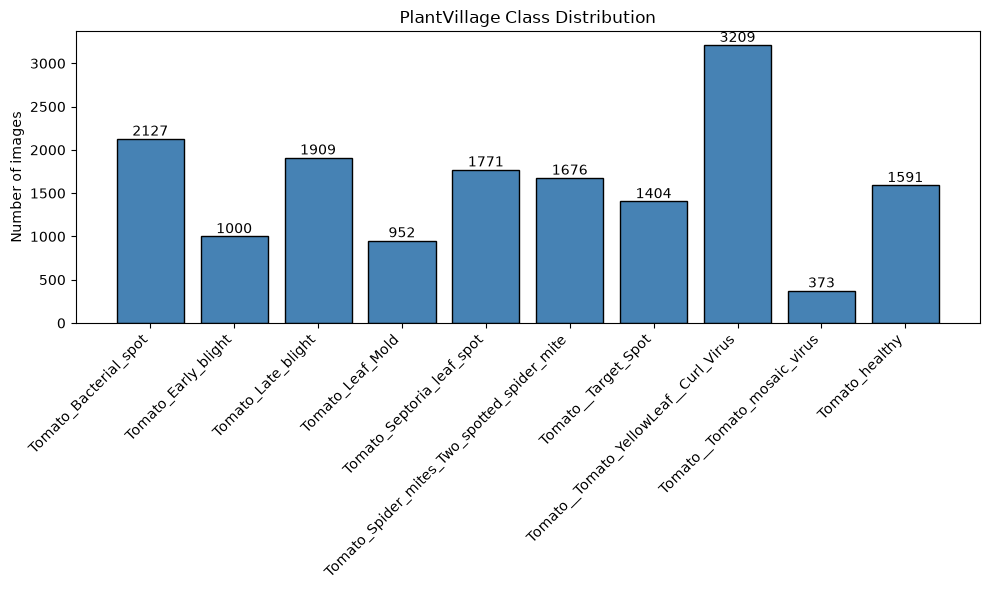

In [5]:
data_dir = "PlantVillage"
classes = sorted(d for d in os.listdir(data_dir) if os.path.isdir(f"{data_dir}/{d}"))
for c in classes:
    print(c, len(os.listdir(f"{data_dir}/{c}")))

counts = [len(os.listdir(f"{data_dir}/{c}")) for c in classes]
plt.figure(figsize=(10, 6))
bars = plt.bar(classes, counts, color="steelblue", edgecolor="black")
plt.bar_label(bars)
plt.xticks(rotation=45, ha="right")
plt.title("PlantVillage Class Distribution")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

In [6]:
# 1. Load the tomato folder (no transform yet, we only need paths and labels)
dataset = datasets.ImageFolder(data_dir)
class_names = dataset.classes

# 2. Separate image paths and labels
all_image_paths = [image_path for image_path, _ in dataset.samples]
all_image_labels = [class_label for _, class_label in dataset.samples]

# 3. Split 1: 80% train, 20% temp
train_paths, temp_paths, train_labels, temp_labels = train_test_split(all_image_paths, all_image_labels, test_size = 0.2, stratify=all_image_labels, random_state=42)

# 4. Split 2: temp into 10% val and 10% test
val_paths, test_paths, val_labels, test_labels = train_test_split(temp_paths, temp_labels, test_size = 0.5, stratify=temp_labels, random_state=42)

# 5. Sanity check
print(f"Train: {len(train_paths)}")
print(f"Validation: {len(val_paths)}")
print(f"Test: {len(test_paths)}")




Train: 12808
Validation: 1601
Test: 1602


In [7]:
IMAGE_SIZE = 128

# Normalize values (standard ImageNet mean and std, fine to use here)
normalize_mean = [0.485, 0.456, 0.406]
normalize_std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0), ratio = (1.0, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(normalize_mean, normalize_std)
])

eval_test_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(normalize_mean, normalize_std)
])

# 1. Three ImageFolder datasets, each with its own transform
train_dataset = datasets.ImageFolder(data_dir, transform = train_transforms)
val_dataset = datasets.ImageFolder(data_dir, transform = eval_test_transforms)
test_dataset = datasets.ImageFolder(data_dir, transform = eval_test_transforms)

# 2. Replace each dataset's image list with its split
train_dataset.samples = list(zip(train_paths, train_labels))
train_dataset.targets = train_labels

val_dataset.samples = list(zip(val_paths, val_labels))
val_dataset.targets = val_labels

test_dataset.samples = list(zip(test_paths, test_labels))
test_dataset.targets = test_labels

# 3. Three dataloaders
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle = True, num_workers = 2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle = False, num_workers = 2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle = False, num_workers = 2)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.6291069].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.6116778].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.6116778].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.6116778].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.6116778].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..0.9319392].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..0.89

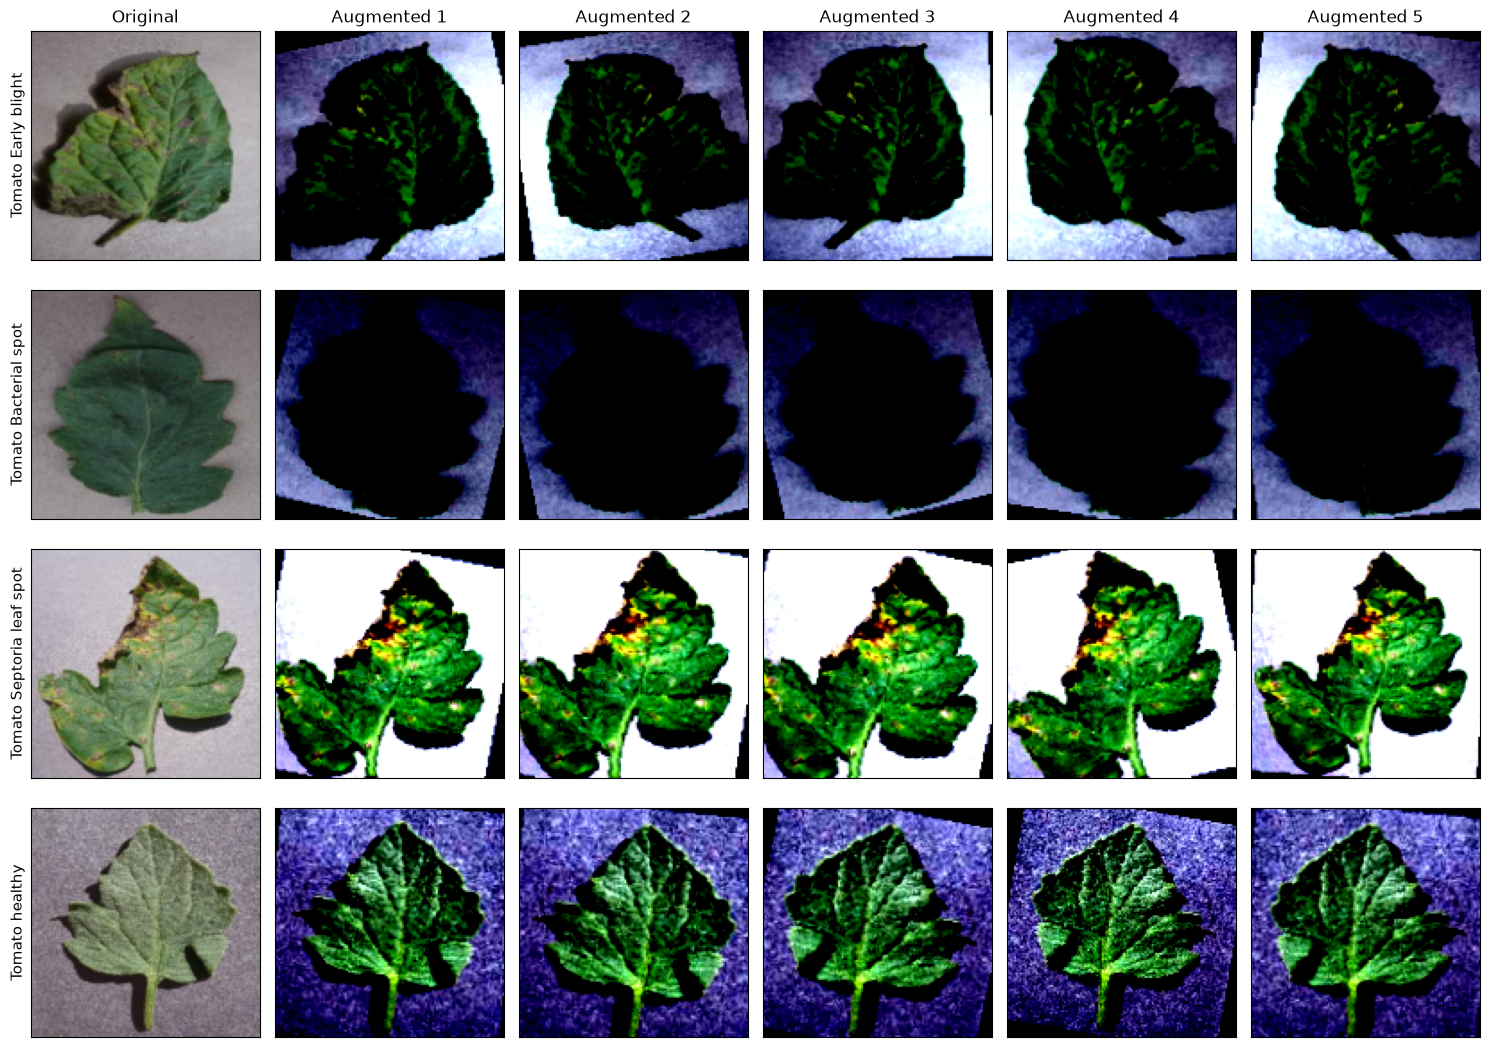

In [8]:
NUM_CLASSES_TO_SHOW = 4
NUM_AUGMENTED_PER_IMAGE = 5

# Pick 4 random classes, one train image from each
random.seed(42)
chosen_class_indices = random.sample(range(len(class_names)), NUM_CLASSES_TO_SHOW)

sample_image_path_per_class = {}
for image_path, class_label in zip(train_paths, train_labels):
    if class_label in chosen_class_indices and class_label not in sample_image_path_per_class:
        sample_image_path_per_class[class_label] = image_path

resize_only = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))

figure, axes = plt.subplots(
    NUM_CLASSES_TO_SHOW, NUM_AUGMENTED_PER_IMAGE + 1,
    figsize=(2.5 * (NUM_AUGMENTED_PER_IMAGE + 1), 2.7 * NUM_CLASSES_TO_SHOW)
)

for row, class_label in enumerate(chosen_class_indices):
    pil_image = Image.open(sample_image_path_per_class[class_label]).convert("RGB")
    readable_class_name = class_names[class_label].replace("Tomato___", "").replace("_", " ")

    axes[row][0].imshow(resize_only(pil_image))
    axes[row][0].set_ylabel(readable_class_name, fontsize=11)

    for column in range(1, NUM_AUGMENTED_PER_IMAGE + 1):
        augmented_tensor = train_transforms(pil_image)
        axes[row][column].imshow(augmented_tensor.permute(1, 2, 0))

axes[0][0].set_title("Original")
for column in range(1, NUM_AUGMENTED_PER_IMAGE + 1):
    axes[0][column].set_title(f"Augmented {column}")

for ax in axes.flatten():
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig("augmentation_grid.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Confirm val and test splits are NOT augmented

for dataset_name, dataset in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]:
    first_load, _ = dataset[0]
    second_load, _ = dataset[0]
    print(dataset_name, "same both times:", torch.equal(first_load, second_load))

train same both times: False
val same both times: True
test same both times: True


In [10]:
# First CNN

class Tomato(nn.Module):
    def __init__(self,num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size = 3, padding = 1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32,64, kernel_size = 3, padding = 1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64,128, kernel_size = 3, padding = 1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2,2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))     
        x = self.pool(F.relu(self.bn2(self.conv2(x))))      
        x = self.pool(F.relu(self.bn3(self.conv3(x))))      


        x = self.adaptive_pool(x)
        x = torch.flatten(x, start_dim=1)        
        x = self.dropout(x)
        return self.fc(x)

# 1. Shape check
model = Tomato(num_classes=len(train_dataset.classes)).to(device)
dummy_batch = torch.randn(4, 3, 128, 128).to(device)
print(model(dummy_batch).shape)  # should be torch.Size([4, 10])

# 2. Initial loss check on one real batch
# images, labels = next(iter(train_loader))
# images, labels = images.to(device), labels.to(device)
# loss = nn.CrossEntropyLoss()(model(images), labels)
# print(loss.item())  # expect roughly 2.3
            

torch.Size([4, 10])


In [10]:
# MODEL TRAIN AND EVAL

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
num_epochs = 35

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    running_correct = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        running_correct += (logits.argmax(dim=1) == labels).sum().item()

    train_loss = running_loss / (len(train_dataset))
    train_acc = running_correct / len(train_dataset)


    #validate
    model.eval()

    val_running_loss = 0.0
    val_running_correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)

            val_running_loss += loss.item() * images.size(0)
            val_running_correct += (logits.argmax(dim=1)==labels).sum().item()

    val_loss = val_running_loss / len(val_dataset)
    val_acc = val_running_correct / len(val_dataset)


    #---record + checkpoint---
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_baseline.pt")

    print(f"epoch {epoch+1}/{num_epochs} | "
          f"train loss {train_loss:.4f} acc {train_acc:.3f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.3f}")

print(f"best val acc: {best_val_acc:.3f}")

epoch 1/35 | train loss 1.1322 acc 0.650 | val loss 0.7577 acc 0.770
epoch 2/35 | train loss 0.7143 acc 0.775 | val loss 0.5985 acc 0.815
epoch 3/35 | train loss 0.5739 acc 0.814 | val loss 0.5830 acc 0.804
epoch 4/35 | train loss 0.4958 acc 0.842 | val loss 0.4622 acc 0.846
epoch 5/35 | train loss 0.4347 acc 0.860 | val loss 0.5161 acc 0.829
epoch 6/35 | train loss 0.4070 acc 0.868 | val loss 0.4266 acc 0.854
epoch 7/35 | train loss 0.3911 acc 0.873 | val loss 0.3243 acc 0.897
epoch 8/35 | train loss 0.3723 acc 0.877 | val loss 0.3673 acc 0.879
epoch 9/35 | train loss 0.3452 acc 0.886 | val loss 0.3630 acc 0.877
epoch 10/35 | train loss 0.3429 acc 0.886 | val loss 0.3601 acc 0.871
epoch 11/35 | train loss 0.3082 acc 0.898 | val loss 0.2507 acc 0.919
epoch 12/35 | train loss 0.2907 acc 0.904 | val loss 0.2862 acc 0.906
epoch 13/35 | train loss 0.2813 acc 0.905 | val loss 0.2313 acc 0.919
epoch 14/35 | train loss 0.2701 acc 0.911 | val loss 0.2057 acc 0.932
epoch 15/35 | train loss 0.25

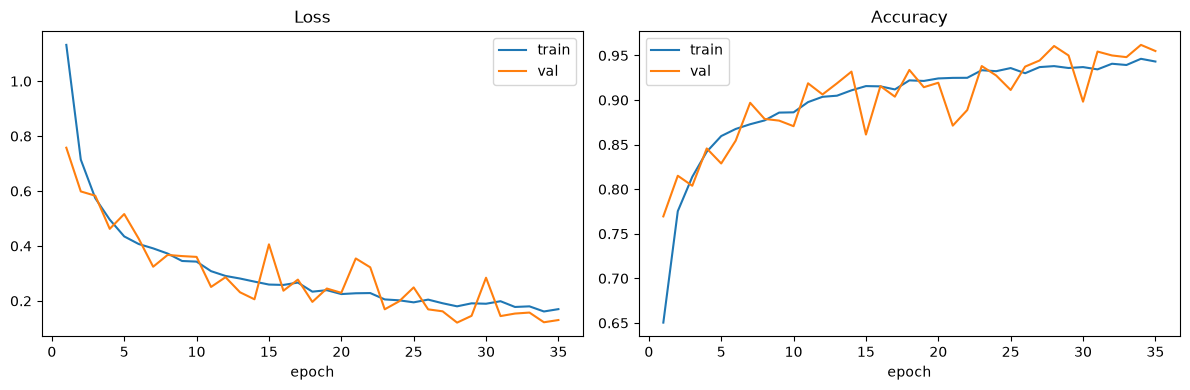

In [ ]:
# baseline curves

import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs_range, history["train_loss"], label="train")
ax_loss.plot(epochs_range, history["val_loss"], label="val")
ax_loss.set_title("Loss")
ax_loss.set_xlabel("epoch")
ax_loss.legend()

ax_acc.plot(epochs_range, history["train_acc"], label="train")
ax_acc.plot(epochs_range, history["val_acc"], label="val")
ax_acc.set_title("Accuracy")
ax_acc.set_xlabel("epoch")
ax_acc.legend()

plt.tight_layout()
plt.savefig("baseline_curves.png", dpi=150)
plt.show()

In [11]:
# RUN 3

# MODEL TRAIN AND EVAL

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

# NEW

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor = 0.5, patience = 3
)
best_val_loss = float('inf')
epochs_without_improvement = 0
early_stopping_patience = 7

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
num_epochs = 40

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    running_correct = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        running_correct += (logits.argmax(dim=1) == labels).sum().item()

    train_loss = running_loss / (len(train_dataset))
    train_acc = running_correct / len(train_dataset)


    #validate
    model.eval()

    val_running_loss = 0.0
    val_running_correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)

            val_running_loss += loss.item() * images.size(0)
            val_running_correct += (logits.argmax(dim=1)==labels).sum().item()

    val_loss = val_running_loss / len(val_dataset)
    val_acc = val_running_correct / len(val_dataset)


    #---record + checkpoint---
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    scheduler.step(val_loss)
    current_learning_rate = optimizer.param_groups[0]['lr']

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), "best_improved.pt")
    else:
        epochs_without_improvement += 1

    print(f"epoch {epoch+1}/{num_epochs} | "
          f"train loss {train_loss:.4f} acc {train_acc:.3f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.3f} | "
          f"lr {current_learning_rate:.6f}")

    if epochs_without_improvement >= early_stopping_patience:
        print(f"early stopping at epoch {epoch+1}")
        break

print(f"best val loss: {best_val_loss:.3f}")

epoch 1/40 | train loss 1.1322 acc 0.650 | val loss 0.7574 acc 0.771 | lr 0.001000
epoch 2/40 | train loss 0.7141 acc 0.775 | val loss 0.6020 acc 0.813 | lr 0.001000
epoch 3/40 | train loss 0.5738 acc 0.814 | val loss 0.5812 acc 0.804 | lr 0.001000
epoch 4/40 | train loss 0.4956 acc 0.843 | val loss 0.4589 acc 0.847 | lr 0.001000
epoch 5/40 | train loss 0.4344 acc 0.860 | val loss 0.5001 acc 0.830 | lr 0.001000
epoch 6/40 | train loss 0.4068 acc 0.867 | val loss 0.4368 acc 0.854 | lr 0.001000
epoch 7/40 | train loss 0.3911 acc 0.873 | val loss 0.3270 acc 0.897 | lr 0.001000
epoch 8/40 | train loss 0.3723 acc 0.877 | val loss 0.3688 acc 0.879 | lr 0.001000
epoch 9/40 | train loss 0.3454 acc 0.886 | val loss 0.3578 acc 0.879 | lr 0.001000
epoch 10/40 | train loss 0.3429 acc 0.887 | val loss 0.3609 acc 0.871 | lr 0.001000
epoch 11/40 | train loss 0.3083 acc 0.897 | val loss 0.2521 acc 0.919 | lr 0.001000
epoch 12/40 | train loss 0.2907 acc 0.904 | val loss 0.2849 acc 0.906 | lr 0.001000
e

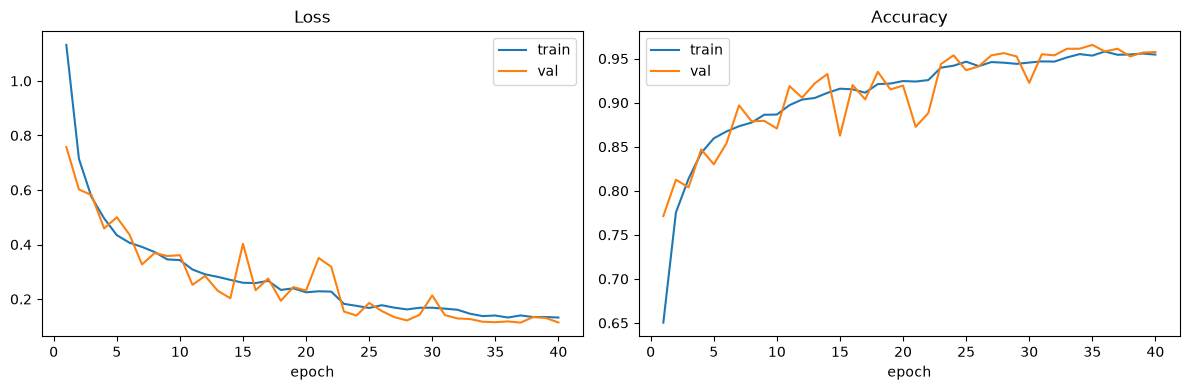

In [ ]:
# curves improved

import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs_range, history["train_loss"], label="train")
ax_loss.plot(epochs_range, history["val_loss"], label="val")
ax_loss.set_title("Loss")
ax_loss.set_xlabel("epoch")
ax_loss.legend()

ax_acc.plot(epochs_range, history["train_acc"], label="train")
ax_acc.plot(epochs_range, history["val_acc"], label="val")
ax_acc.set_title("Accuracy")
ax_acc.set_xlabel("epoch")
ax_acc.legend()

plt.tight_layout()
plt.savefig("curves_improved.png", dpi=150)
plt.show()

In [14]:
# Test eval

model = Tomato(num_classes=len(train_dataset.classes)).to(device)
model.load_state_dict(torch.load("best_improved.pt"))
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

correct = sum(p == l for p, l in zip(all_predictions, all_labels))
test_accuracy = correct / len(all_labels)
print(f"test accuracy: {test_accuracy:.4f}")

test accuracy: 0.9600


                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.971     0.958     0.965       213
                        Tomato_Early_blight      0.890     0.970     0.928       100
                         Tomato_Late_blight      0.983     0.895     0.937       191
                           Tomato_Leaf_Mold      0.969     0.979     0.974        95
                  Tomato_Septoria_leaf_spot      0.966     0.977     0.972       177
Tomato_Spider_mites_Two_spotted_spider_mite      0.987     0.935     0.960       168
                        Tomato__Target_Spot      0.936     0.936     0.936       141
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.984     0.981     0.983       321
                Tomato__Tomato_mosaic_virus      0.881     1.000     0.937        37
                             Tomato_healthy      0.924     1.000     0.961       159

                                   accuracy                    

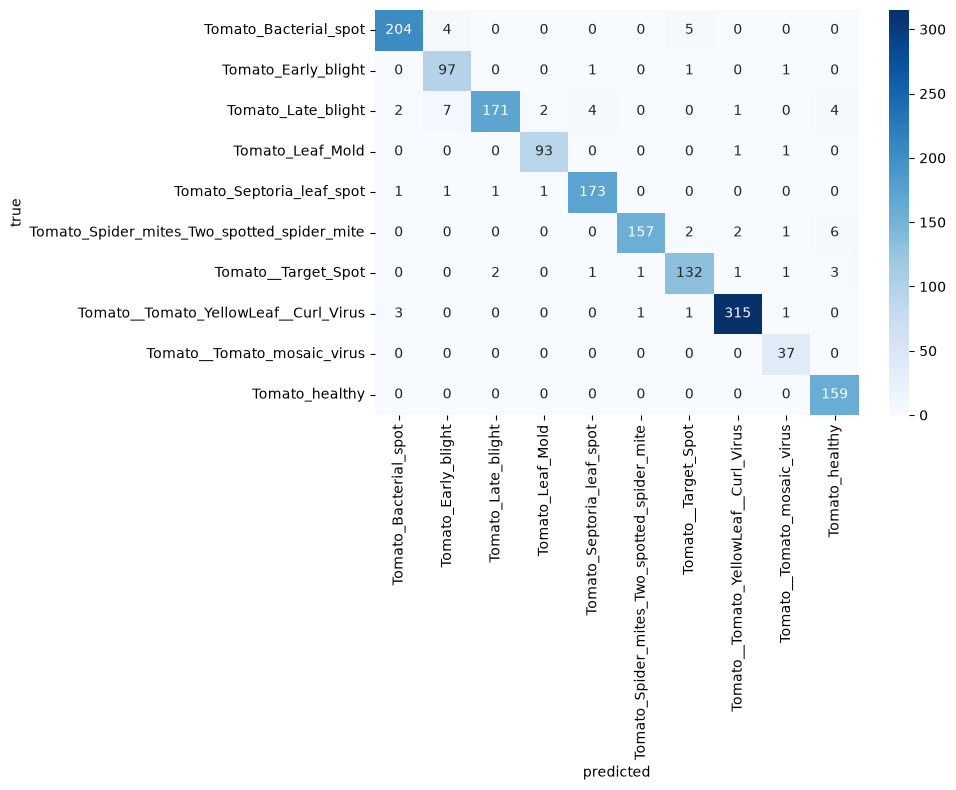

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

class_names = test_dataset.classes
print(classification_report(all_labels, all_predictions, target_names=class_names, digits=3))

matrix = confusion_matrix(all_labels, all_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(matrix, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("predicted")
plt.ylabel("true")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

64
64


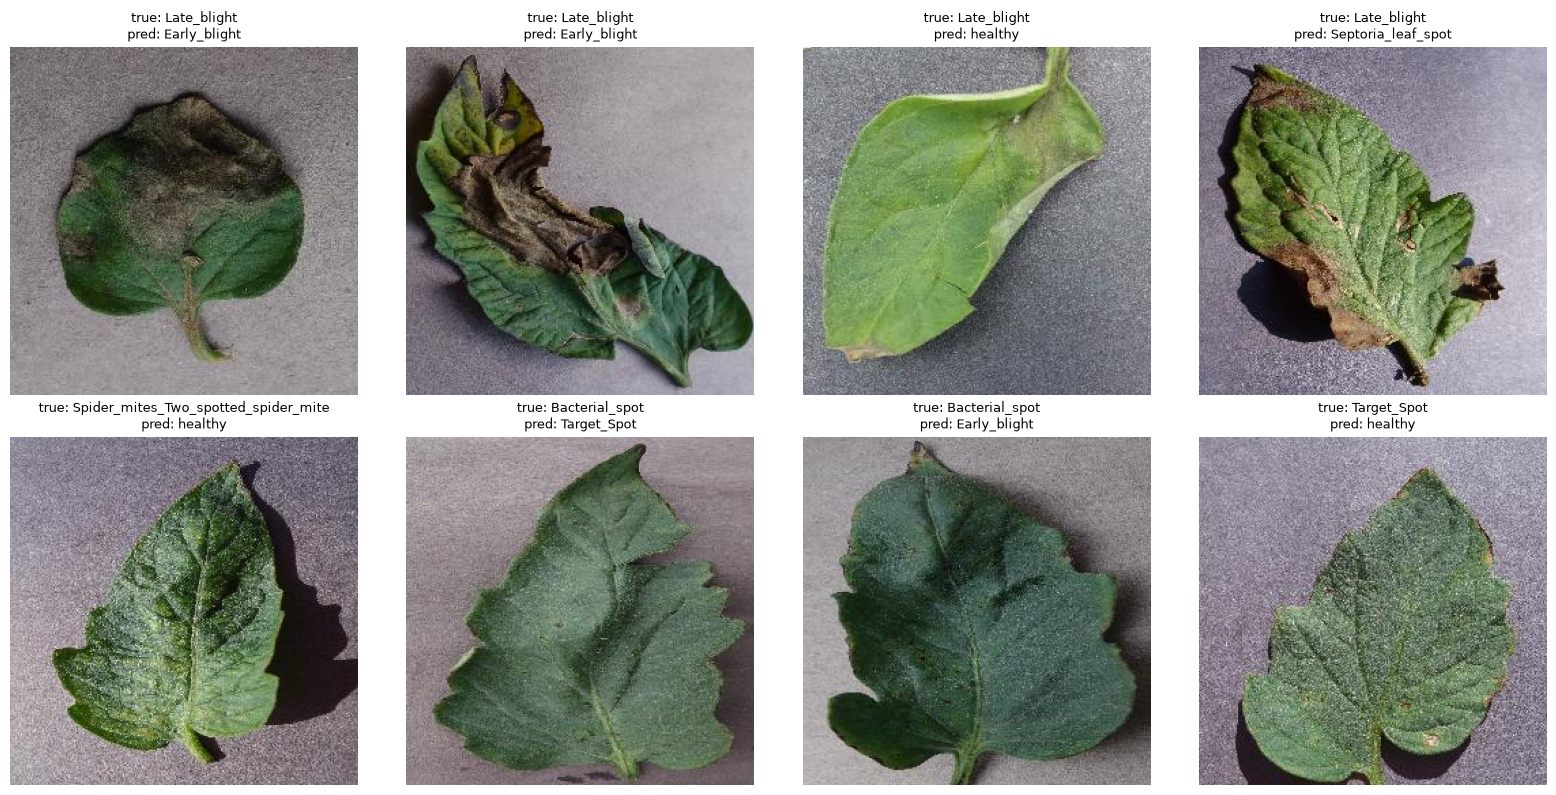

[200, 280, 170, 578, 533, 152, 237, 149]


In [17]:
wrong_indices = [i for i, (p, l) in enumerate(zip(all_predictions, all_labels)) if p != l]
print(len(wrong_indices))  # should be 64

short_class_names = [
    name.replace("Tomato__", "").replace("Tomato_", "")
    for name in test_dataset.classes
]

wrong_indices = [
    index for index, (predicted, true) in enumerate(zip(all_predictions, all_labels))
    if predicted != true
]
print(len(wrong_indices))  # should be 64

# (true class, predicted class, how many examples to show)
requested_confusions = [
    ("Late_blight", "Early_blight", 2),
    ("Late_blight", "healthy", 1),
    ("Late_blight", "Septoria_leaf_spot", 1),
    ("Spider_mites_Two_spotted_spider_mite", "healthy", 1),
    ("Bacterial_spot", "Target_Spot", 1),
    ("Bacterial_spot", "Early_blight", 1),
    ("Target_Spot", "healthy", 1),
]

selected_wrong_indices = []
for true_name, predicted_name, how_many in requested_confusions:
    true_index = short_class_names.index(true_name)
    predicted_index = short_class_names.index(predicted_name)
    matching_indices = [
        index for index in wrong_indices
        if all_labels[index] == true_index and all_predictions[index] == predicted_index
    ]
    selected_wrong_indices.extend(matching_indices[:how_many])

figure, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis in axes.flat:
    axis.axis("off")

for axis, sample_index in zip(axes.flat, selected_wrong_indices):
    image_path = test_dataset.samples[sample_index][0]
    axis.imshow(Image.open(image_path))
    axis.set_title(
        f"true: {short_class_names[all_labels[sample_index]]}\n"
        f"pred: {short_class_names[all_predictions[sample_index]]}",
        fontsize=9,
    )

plt.tight_layout()
plt.savefig("wrong_predictions.png", dpi=150)
plt.show()

print(selected_wrong_indices)  # keep these, we reuse them for Grad-CAM

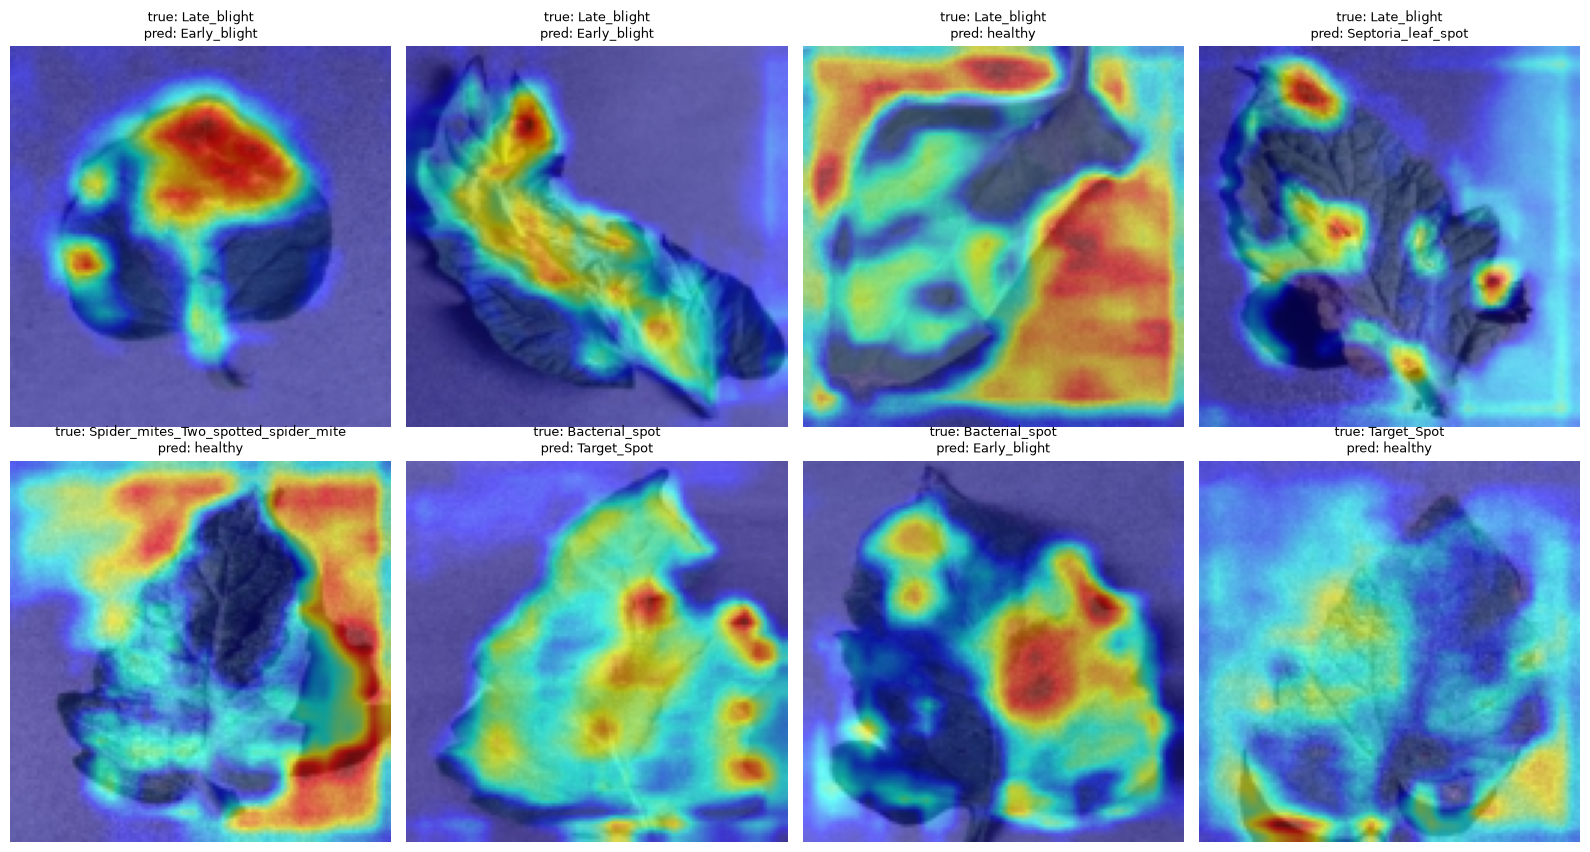

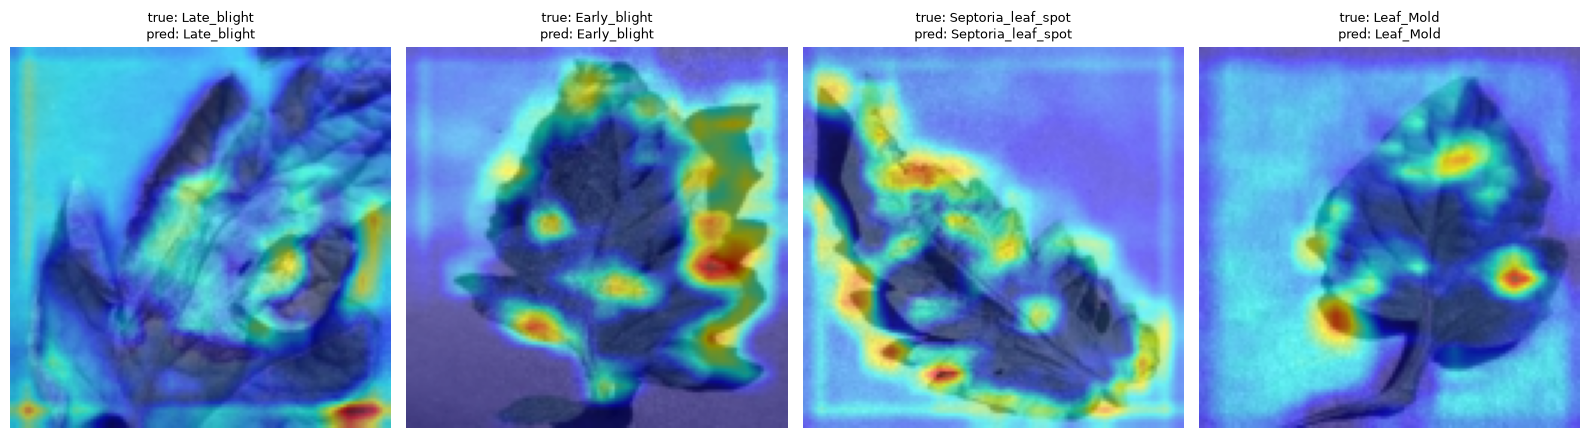

In [19]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

cam = GradCAM(model=model, target_layers=[model.bn3])
imagenet_mean = np.array([0.485, 0.456, 0.406])
imagenet_std = np.array([0.229, 0.224, 0.225])

def make_gradcam_overlay(sample_index):
    image_tensor, _ = test_dataset[sample_index]
    heatmap = cam(input_tensor=image_tensor.unsqueeze(0).to(device), targets=None)[0]
    rgb_image = image_tensor.permute(1, 2, 0).numpy() * imagenet_std + imagenet_mean
    rgb_image = np.clip(rgb_image, 0, 1).astype(np.float32)
    return show_cam_on_image(rgb_image, heatmap, use_rgb=True)

def plot_gradcam_grid(sample_indices, rows, columns, filename):
    figure, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4.3 * rows))
    flat_axes = np.array(axes).flatten()
    for axis in flat_axes:
        axis.axis("off")
    for axis, sample_index in zip(flat_axes, sample_indices):
        axis.imshow(make_gradcam_overlay(sample_index))
        axis.set_title(
            f"true: {short_class_names[all_labels[sample_index]]}\n"
            f"pred: {short_class_names[all_predictions[sample_index]]}",
            fontsize=9,
        )
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

# wrong predictions (same 8 images as before)
plot_gradcam_grid(selected_wrong_indices, 2, 4, "gradcam_wrong.png")

# correct predictions: first correctly classified image of each class
correct_class_names = ["Late_blight", "Early_blight", "Septoria_leaf_spot", "Leaf_Mold"]
correct_indices = []
for class_name in correct_class_names:
    class_index = short_class_names.index(class_name)
    for sample_index, (predicted, true) in enumerate(zip(all_predictions, all_labels)):
        if predicted == true == class_index:
            correct_indices.append(sample_index)
            break

plot_gradcam_grid(correct_indices, 1, 4, "gradcam_correct.png")

In [20]:
import json

class_names = train_dataset.classes

with open("class_names.json", "w") as file:
    json.dump(class_names, file)

print(len(class_names), "classes saved")
print(class_names)

10 classes saved
['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [21]:
import os
import shutil
import random

random.seed(42)
os.makedirs("samples", exist_ok=True)

for class_index, class_name in enumerate(test_dataset.classes):
    class_paths = [path for path, label in test_dataset.samples if label == class_index]
    chosen_path = random.choice(class_paths)
    new_name = f"{class_name}__{os.path.basename(chosen_path)}"
    shutil.copy(chosen_path, os.path.join("samples", new_name))

print(os.listdir("samples"))

['Tomato_Bacterial_spot__c8915550-70f9-43d9-b747-e7a70bec5d3f___GCREC_Bact.Sp 3009.JPG', 'Tomato_Early_blight__e3b74c49-7e82-4094-8a02-5ae7644a1d00___RS_Erly.B 7393.JPG', 'Tomato_healthy__a98d00cf-f048-44d7-b82b-3328a8e891b3___RS_HL 0585.JPG', 'Tomato_Late_blight__da40dbcb-5ed7-428a-9c64-34c0b6ab7219___GHLB2 Leaf 9009.JPG', 'Tomato_Leaf_Mold__d633dfc9-74f2-4fbc-b540-3b87a53807d0___Crnl_L.Mold 9106.JPG', 'Tomato_Septoria_leaf_spot__36dd8cd2-dd26-40a2-b25c-f4ce6d94f6be___Keller.St_CG 1845.JPG', 'Tomato_Spider_mites_Two_spotted_spider_mite__06c29099-98e3-46ae-88f9-7160c74dafea___Com.G_SpM_FL 9427.JPG', 'Tomato__Target_Spot__a11d867b-0cb9-4bc8-a96a-98dad0085c09___Com.G_TgS_FL 0653.JPG', 'Tomato__Tomato_mosaic_virus__eec8df45-9f5b-4121-a630-8088c5422efd___PSU_CG 2157.JPG', 'Tomato__Tomato_YellowLeaf__Curl_Virus__76874a03-c2f4-4d8c-ba99-26df6fa4b289___UF.GRC_YLCV_Lab 03228.JPG']
